# Jobs

In [16]:
from pathlib import Path
from joblib import load
import numpy as np
import pandas as pd
import seaborn as sns 
import scanpy as sc
import matplotlib.pyplot as plt
import string, os
from collections import Counter 
import logomaker

colors_to_use=[(0.34550725069638827, 0.4203708006658883, 0.9696902293486781),
 (0.9893800026041992, 0.378955911742755, 0.21756841368122667),
 (0.3959642074605608, 0.24823947872676938, 0.4016676539297192),
 (0.9937826924994482, 0.4211527500079969, 0.8812994030921271),
 (0.4140058397372807, 0.9619317608252869, 0.3109026417629064),
 (0.2286247431221609, 0.6437632542888629, 0.4081322805120583),
 (0.25003260615661993, 0.938691496932296, 0.9192515923797947),
 (0.7646511697684856, 0.24254983894398235, 0.7085129830496552),
 (0.3017721221187747, 0.6522700618245787, 0.9844707721904342),
 (0.21782892631529166, 0.2854088109905996, 0.7174819557293214),
 (0.9991896546476063, 0.4844986464266022, 0.5344476773522967),
 (0.8919236560192338, 0.7949117963224906, 0.7730486745511909),
 (0.6428145648345002, 0.31108252586505475, 0.2041098261347507),
 (0.20269999368314223, 0.7748472379028853, 0.6824940025160084),
 (0.9819923318374866, 0.6965816490867496, 0.21263663000131983),
 (0.809020033101876, 0.23056728504993104, 0.9541856467035792),
 (0.9191255237720919, 0.20589563833687236, 0.4656154484972612),
 (0.4066816185888487, 0.7781338620666193, 0.22302116197384453),
 (0.9393586762460103, 0.9614694589148117, 0.22619331869433382),
 (0.29226458048518345, 0.42830335364029093, 0.6916335500700534)]
	

colors_to_use_pastel=[(0.5665516830630946, 0.5037138904751852, 0.5075215212500083),
 (0.9949012052279167, 0.7553237006975844, 0.5055095027008268),
 (0.6013710840316495, 0.6764106146805113, 0.9895579386673582),
 (0.998816092724718, 0.7071878014442006, 0.8979090191443285),
 (0.5429870427410571, 0.750719571440085, 0.6124765491924715),
 (0.5084695919264852, 0.5093366344721296, 0.9990436978593071),
 (0.8246194014837736, 0.9846839170837028, 0.5089892119497516),
 (0.5052972476002842, 0.5444186786858283, 0.7812964942323839),
 (0.5124601533942488, 0.9750384643760528, 0.9697621879182152),
 (0.9728598314959997, 0.5013134514042519, 0.8469604310077152)]
celltypes=["T","B","NK","DC","Monocytes"]

In [2]:
adata=sc.read_h5ad("Datasets/PBMC/CM/PBMC_Peak_Def.h5ad")
adata

AnnData object with n_obs × n_vars = 6180 × 63906
    obs: 'RNA_celltype', 'Raw_CellType', 'CellType', 'nucleosome_signal', 'tss_enrichment_score', 'n_features', 'log_n_features', 'n_counts', 'log_n_counts', 'passes_filter'
    var: 'chr', 'start', 'stop', 'n_cells', 'log_n_cells', 'passes_filter', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm'
    uns: 'fragment_lengths', 'hvg', 'tss_enrichment'
    layers: 'counts'

In [ ]:
celltypes=["T","B","NK","DC","Monocytes"]
for key in marker_genes_by_celltype:
    print(key)
    ad_red=adata[adata.obs.Raw_CellType==key, adata.var.highly_variable==True].copy()
    os.system(f"mkdir -p Datasets/PBMC/TDA_CellType_Peak/{key}")
    ad_red.write(f"Datasets/PBMC/TDA_CellType_Peak/{key}/PBMC_Peak_{key}.h5ad", compression="gzip")

In [ ]:
import os
for key in marker_genes_by_celltype.keys():
    print(key)
    os.system(f"sbatch -p slim18 -J TDA{key} --mem=64G --ntasks=1 --cpus-per-task=8 --time 7-00:00:00 --exclusive\
                --output=Datasets/PBMC/PBMC_{key}_Run_scTDA_Peak.out Run_Exp.sh Run_scTDA_Peak Datasets/PBMC/TDA_CellType_Peak/{key}/PBMC_Peak_{key}.h5ad Datasets/PBMC/TDA_CellType_Peak/{key} {key}")

In [11]:
import os
for key in celltypes:
    print(key)
    os.system(f"sbatch -p slim18 -J hTDA{key} --mem=64G --ntasks=1 --cpus-per-task=12 --time 7-00:00:00\
                --output=Datasets/PBMC/PBMC_{key}_Run_scTDA_Peak_HOMER.out Run_Exp.sh \
                HOMER Datasets/PBMC/TDA_CellType_Peak/{key} ../AnnotRef/hs/T2T/chm13v2.0.fa 150")

T
Submitted batch job 1557645
B
Submitted batch job 1557646
NK
Submitted batch job 1557647
DC
Submitted batch job 1557648
Monocytes
Submitted batch job 1557649


In [13]:
os.system(f"cat Datasets/PBMC/PBMC_{key}_Run_scTDA_Peak_HOMER.out")

0

In [10]:
f"Datasets/PBMC/PBMC_{key}_Run_scTDA_Peak_HOMER.out"

'Datasets/PBMC/PBMC_Monocytes_Run_scTDA_Peak_HOMER.out'

# Persistence diagrams

In [31]:
ROOT=Path("Datasets/PBMC/TDA_CellType_Peak/")
all_results={}

for celltype_dir in ROOT.iterdir():
    if not celltype_dir.is_dir(): continue
    celltype=celltype_dir.name
    print(f"Loading {celltype}")
    all_results[celltype]={}

    tda_path=celltype_dir/f"{celltype}_H_tda.joblib"
    tda=load(tda_path) if tda_path.exists() else None
    if tda is None: print(f"Missing: {tda_path}")

    for H in [0,1,2]:
        prefix=f"{celltype}_H{H}"
        objs={"tda":tda}

        for key in ["x_tda","results"]:
            path=celltype_dir/f"{prefix}_{key}.joblib"
            objs[key]=load(path) if path.exists() else None
            if objs[key] is None: print(f"Missing: {path}")

        all_results[celltype][f"H{H}"]=objs

Loading Monocytes
Loading B
Loading T
Loading NK
Loading DC


Plotting T


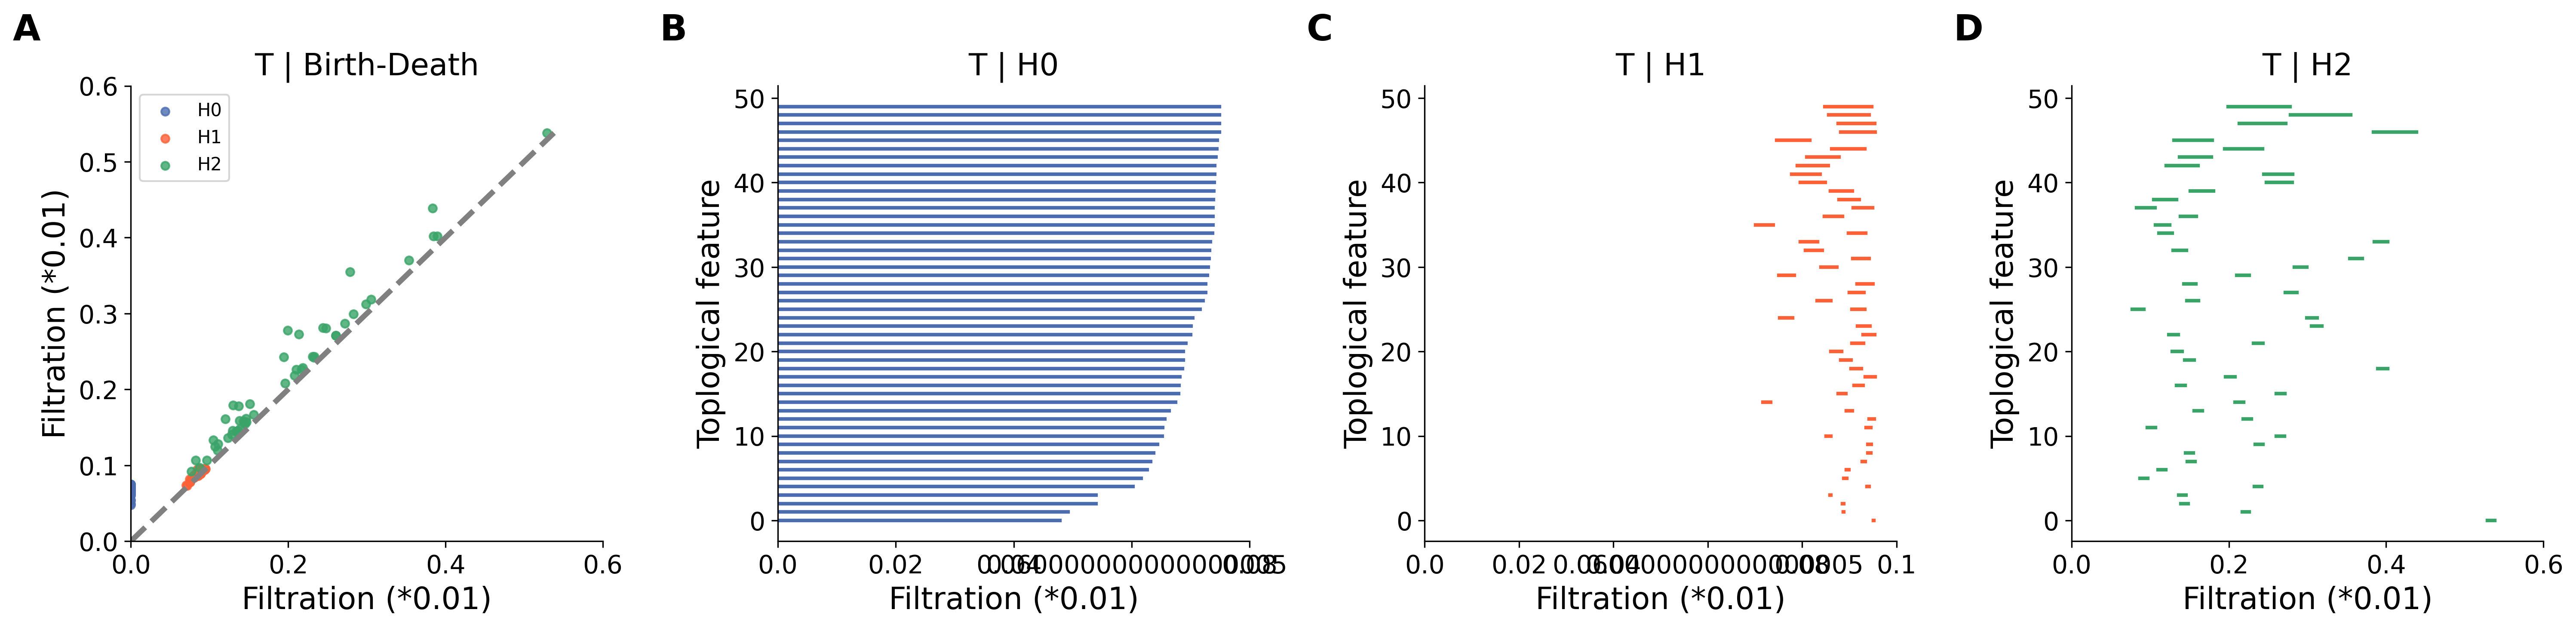

Plotting B


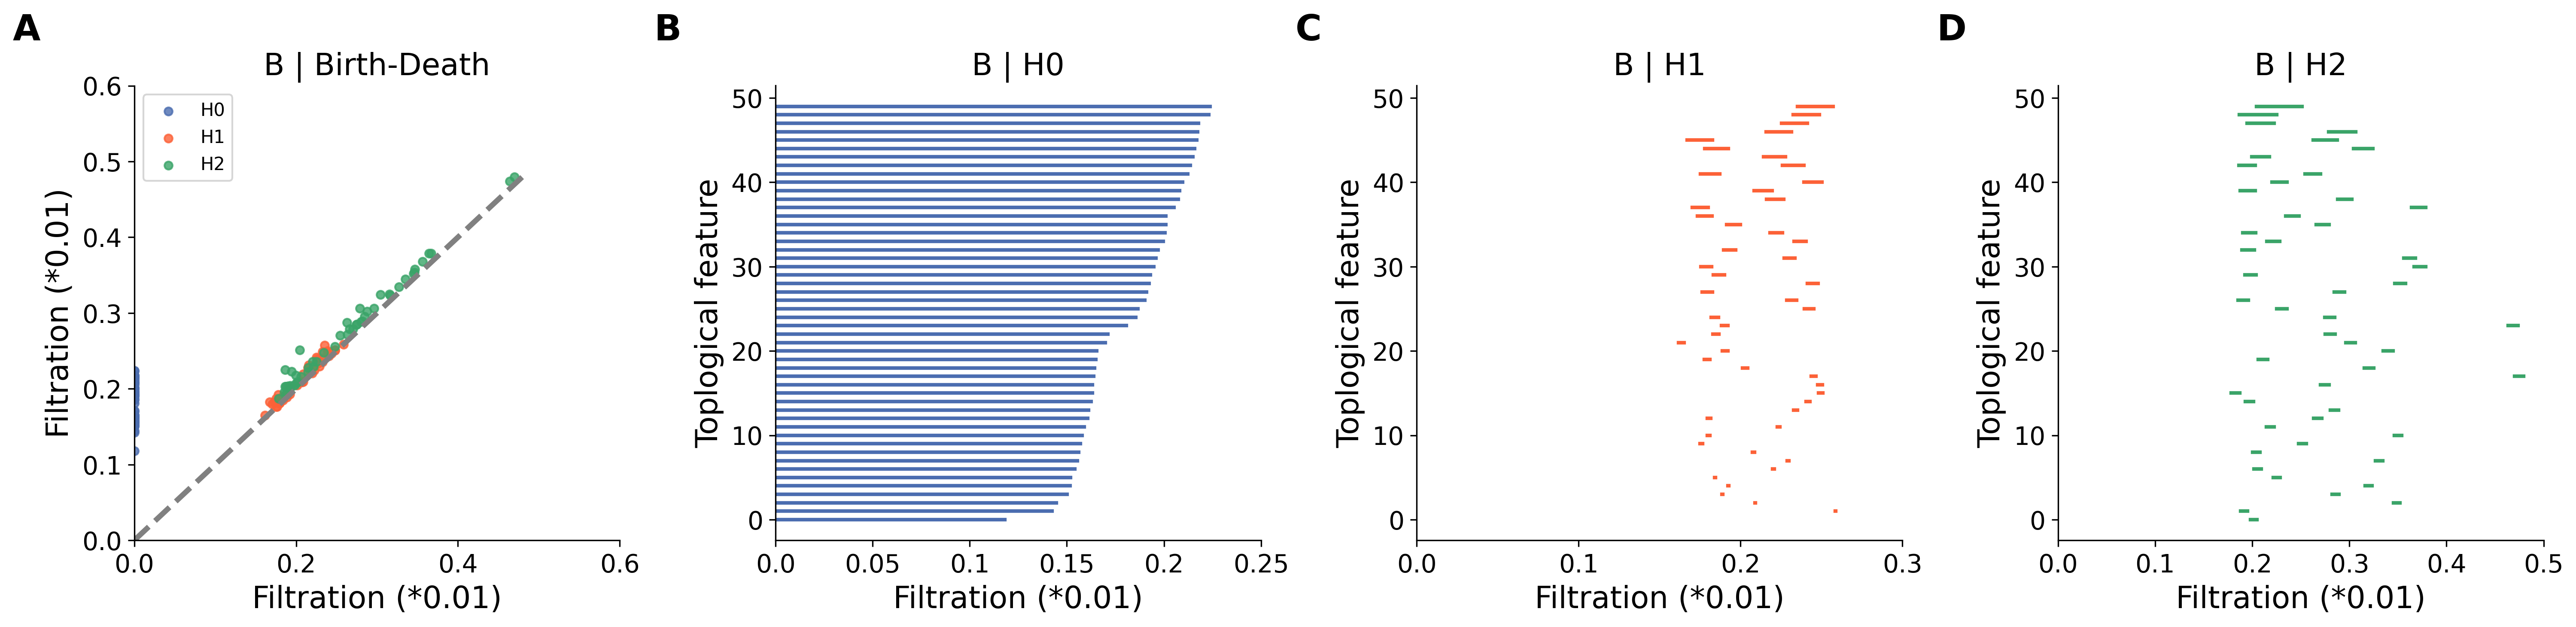

Plotting NK


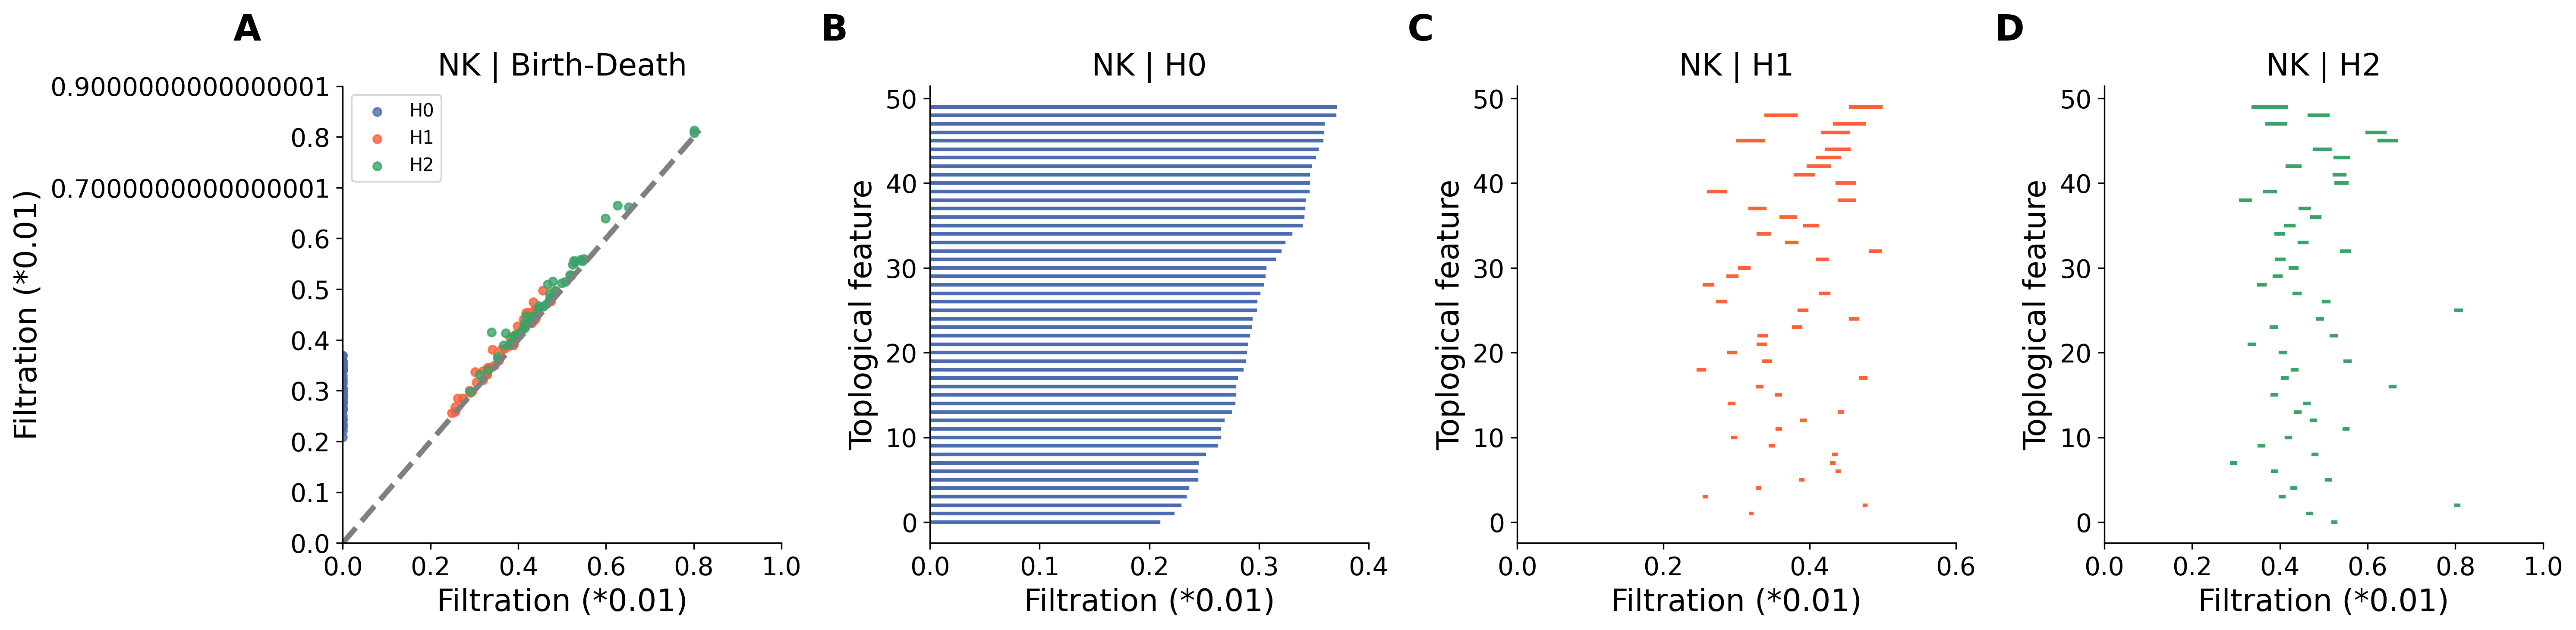

Plotting DC


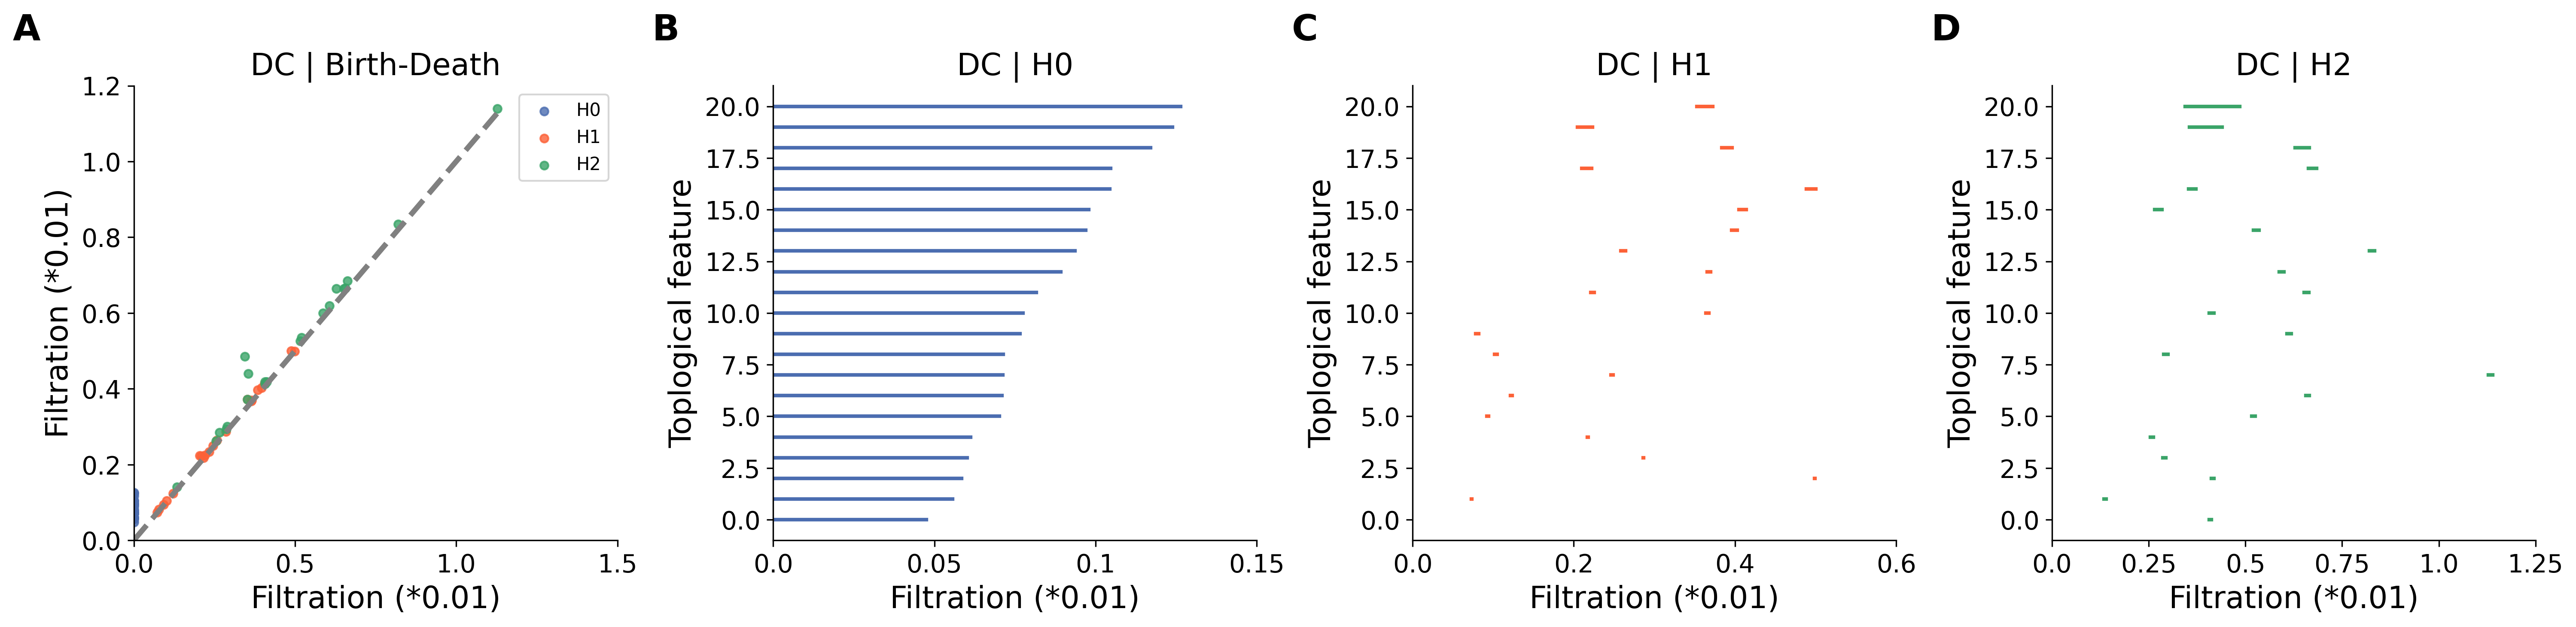

Plotting Monocytes


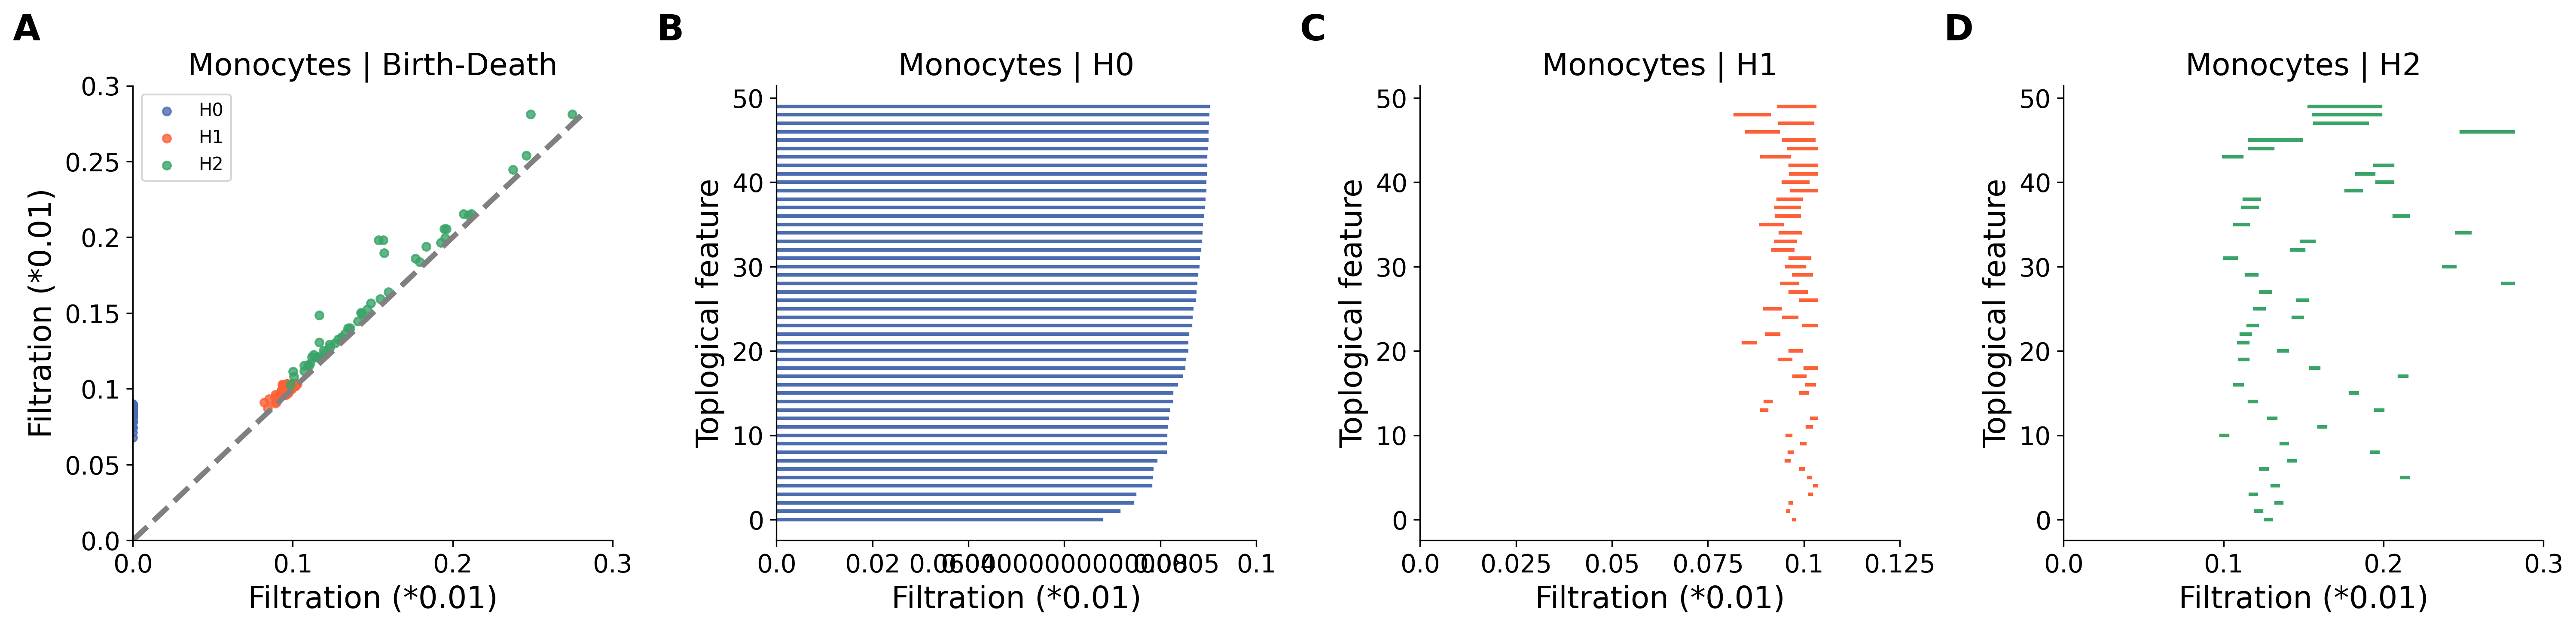

In [37]:
colors=[(0.29226458048518345,0.42830335364029093,0.6916335500700534),
        (0.9893800026041992,0.378955911742755,0.21756841368122667),
        (0.2286247431221609,0.6437632542888629,0.4081322805120583)]    
labels=["H0","H1","H2"]
params = {
    'axes.labelsize': 17,
    'axes.titlesize': 17,
    'xtick.labelsize': 14,
    'ytick.labelsize': 14,
    "lines.linewidth": 3,
    "figure.dpi": 300}
plt.rcParams.update(params)

for celltype in celltypes:
    print(f"Plotting {celltype}")

    tda=all_results[celltype]["H2"]["tda"]
    x_tda=all_results[celltype]["H2"]["x_tda"]

    features=[f for f in tda.features[2] if np.isfinite(f["persistence"])]
    features=sorted(features,key=lambda x:x["persistence"],reverse=True)

    n_select=int(np.ceil(0.5*len(features)))
    if hasattr(x_tda,"max_features"): n_select=min(n_select,x_tda.max_features)

    selected_ids=set(f["feature_id"] for f in features[:n_select])

    dgms_plot=[]
    for dim in range(3):
        dgm=tda.dgms[dim]
        feature_ids_dim=set(f["feature_id"] for f in tda.features[dim] if f["feature_id"] in selected_ids)
        keep_idx=[i for i in range(len(dgm)) if i in feature_ids_dim]
        dgms_plot.append(dgm[keep_idx])

    fig,axes=plt.subplots(1,4,figsize=(20,5))

    ax=axes[0]
    max_val=max([np.max(dgm[np.isfinite(dgm[:,1])]) for dgm in dgms_plot if len(dgm)>0 and np.any(np.isfinite(dgm[:,1]))],default=0)

    for dim in range(3):
        dgm=dgms_plot[dim].copy()
        if len(dgm)==0: continue
        dgm[~np.isfinite(dgm[:,1]),1]=max_val
        ax.scatter(dgm[:,0],dgm[:,1],s=20,alpha=0.8,color=colors[dim],label=labels[dim])

    ax.plot([0,max_val],[0,max_val],"--",color="gray")
    ax.set(title=f"{celltype} | Birth-Death", xlabel="Birth [Filtration value]", ylabel="Death [Filtration value]")
    ax.legend()

    for dim in range(3):
        ax=axes[dim+1]
        dgm=dgms_plot[dim].copy()
        if len(dgm)==0: continue

        dgm=dgm[np.argsort(dgm[:,1]-dgm[:,0])]

        for i,(birth,death) in enumerate(dgm):
            if not np.isfinite(death): death=max_val
            ax.plot([birth,death],[i,i],color=colors[dim],lw=2)

        ax.set(title=f"{celltype} | H{dim}", xlabel="Filtration", ylabel="Toplogical feature")

    for l,ax in enumerate(axes): 
        ax.annotate(string.ascii_uppercase[l],xy=(-0.25,1.1),xycoords="axes fraction",fontsize=20,fontweight="bold",ha="left")  
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False) 
        ax.set_xlim([0, ax.get_xticks().max()])
        ax.set_xticks(ax.get_xticks(), np.array(ax.get_xticks()*100).astype(str))
        ax.set_xlabel("Filtration (*0.01)")

    axes[0].set_ylim([0, axes[0].get_yticks().max()])
    axes[0].set_yticks(axes[0].get_yticks(), np.array(axes[0].get_yticks()*100).astype(str))
    axes[0].set_ylabel("Filtration (*0.01)")
    
    plt.tight_layout()
    plt.savefig(f"Figures/PBMC_Birth_Death_Barplot_{celltype}_Peak.png", format="png", dpi=300, bbox_inches='tight')

    plt.show()

# Results

In [14]:
celltypes=["T","B","NK","DC","Monocytes"]
rows = []
for key in celltypes:
    OUTDIR = f"Datasets/PBMC/TDA_CellType_Peak/{key}"
    for H in [0,1,2]:
        hdir = f"{OUTDIR}/HOMER/H_{H}"
        if not os.path.isdir(hdir): continue
    
        for feat in os.listdir(hdir):
            f = f"{hdir}/{feat}/knownResults.txt"
            if not os.path.exists(f): continue
    
            try:
                df = pd.read_csv(f, sep="\t")
                q = next(c for c in df.columns if "Benjamini" in c)
                df = df[df[q] < 0.05]
                rows += [{"motif":r["Motif Name"], "qvalue":r[q], "H":H, "feature":feat, "CellType":key} for _, r in df.iterrows()]
            except: pass

df=pd.DataFrame(rows)#.to_csv(f"{OUTDIR}/HOMER/significant_motifs.tsv", sep="\t", index=False)
df["motif_gene"] = df["motif"].str.extract(r"^([^(/-]+)")
df

,motif,qvalue,H,feature,CellType,motif_gene
0,Fos(bZIP)/TSC-Fos-ChIP-Seq(GSE110950)/Homer,0.0006,0,feature_3290,T,Fos
1,Fli1(ETS)/CD8-FLI-ChIP-Seq(GSE20898)/Homer,0.0006,0,feature_3290,T,Fli1
2,ERG(ETS)/VCaP-ERG-ChIP-Seq(GSE14097)/Homer,0.0006,0,feature_3290,T,ERG
3,BATF(bZIP)/Th17-BATF-ChIP-Seq(GSE39756)/Homer,0.0006,0,feature_3290,T,BATF
4,ETV4(ETS)/HepG2-ETV4-ChIP-Seq(ENCODE)/Homer,0.0006,0,feature_3290,T,ETV4
...,...,...,...,...,...,...
6500,ETV1(ETS)/GIST48-ETV1-ChIP-Seq(GSE22441)/Homer,0.0011,1,feature_3506,Monocytes,ETV1
6501,GABPA(ETS)/Jurkat-GABPa-ChIP-Seq(GSE17954)/Homer,0.0037,1,feature_3506,Monocytes,GABPA
6502,EHF(ETS)/LoVo-EHF-ChIP-Seq(GSE49402)/Homer,0.0108,1,feature_3506,Monocytes,EHF
6503,ELF1(ETS)/Jurkat-ELF1-ChIP-Seq(SRA014231)/Homer,0.0108,1,feature_3506,Monocytes,ELF1


In [15]:
tf_dict = df.groupby("CellType")["motif_gene"].unique().apply(list).to_dict()
cnt = Counter(tf for v in tf_dict.values() for tf in v) 
new_dict = { k: [tf for tf in v if cnt[tf] == 1] for k, v in tf_dict.items() }

for ct, tfs in new_dict.items():
    print(ct, sorted(tfs), "\n")

B ['At3g09600', 'BORIS', 'Brn1', 'EBF', 'EBF1', 'EBF2', 'ERF105', 'ETS:RUNX', 'Elk4', 'Foxa3', 'GTL1', 'HY5', 'KLF5', 'LCL1', 'Lhx6', 'MNT', 'MYB39', 'MYB3R5', 'Mef2d', 'Oct4', 'Oct6', 'PAX5', 'SPL11', 'STAT1', 'STOP1', 'Snail1', 'TGA5', 'Tlx?', 'Unknown4', 'VIP1', 'X', 'ZNF341'] 

DC ['ABF2', 'AREB3', 'AT2G31460', 'At1g13300', 'At1g22810', 'GAGA', 'GBF3', 'GBF6', 'HAT1', 'Hoxa9', 'MYB101', 'MYB116', 'MYB62', 'MYB96', 'Pitx1:Ebox', 'Replumless', 'STAT5', 'ZBTB18', 'bZIP28', 'bZIP48', 'bZIP53', 'hTCT'] 

Monocytes ['ATHB15', 'ATHB20', 'ATHB53', 'Hoxa10', 'Rfx6', 'ZNF528'] 

NK ['AGL13', 'AT1G44830', 'AT1G71450', 'AT5G22990', 'At1g19210', 'At1g36060', 'At2g41835', 'At5g18450', 'CEJ1', 'DEAR2', 'DREB19', 'DREB2', 'DREB26', 'NF', 'NF1', 'RKD2', 'RORg', 'Tbet', 'Tbx6', 'WRKY20', 'WRKY25', 'WRKY26', 'WRKY3', 'WRKY75', 'ZNF768', 'ZNF91', 'bZIP52'] 

T ['AT1G76870', 'LEF1', 'SND3', 'Tbx5', 'Tcf4', 'WUS1'] 



In [22]:
# =========================================================
# Targets
# =========================================================

targets = {
    "B": ["EBF", "PAX5"],
    "T": ["LEF1"],
    "DC": ["STAT5"]
}

# =========================================================
# HOMER root
# =========================================================

ROOT = "Datasets/PBMC/TDA_CellType_Peak"

# =========================================================
# Read HOMER PWM
# =========================================================

def read_homer_motif(path):

    rows = []

    with open(path) as f:

        for i, line in enumerate(f):

            if i == 0: continue

            vals = line.strip().split()

            if len(vals) != 4: continue

            rows.append([float(x) for x in vals])

    pwm = pd.DataFrame(rows, columns=["A","C","G","T"])

    return pwm

B | EBF -> Datasets/PBMC/TDA_CellType_Peak/B/HOMER/H_0/feature_572/knownResults/known13.motif
B | PAX5 -> Datasets/PBMC/TDA_CellType_Peak/B/HOMER/H_0/feature_570/knownResults/known10.motif
T | LEF1 -> Datasets/PBMC/TDA_CellType_Peak/T/HOMER/H_1/feature_4130/knownResults/known20.motif
DC | STAT5 -> Datasets/PBMC/TDA_CellType_Peak/DC/HOMER/H_1/feature_29/knownResults/known18.motif


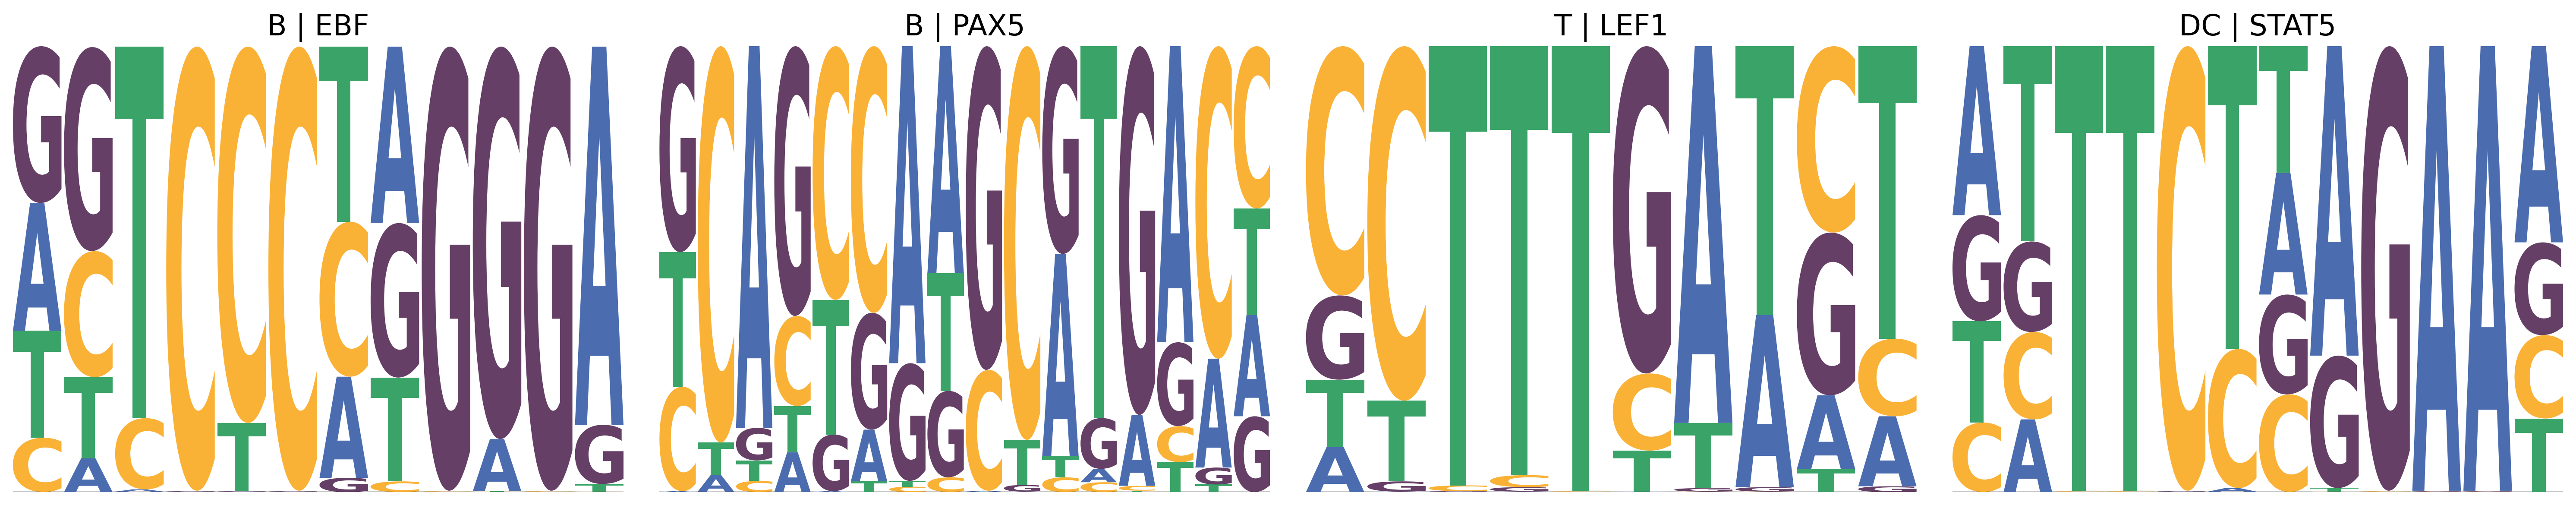

In [30]:
# =========================================================
# Plot
# =========================================================
dna_colors = {
    "A": colors_to_use[19],
    "C": colors_to_use[14],
    "G": colors_to_use[2],
    "T": colors_to_use[5]
}
fig, axes = plt.subplots(1,4,figsize=(20,4), dpi=300)

k = 0

for ct, tfs in targets.items():

    for tf in tfs:

        # -------------------------------------------------
        # Retrieve feature from df
        # -------------------------------------------------

        row = df[(df["CellType"] == ct) & (df["motif_gene"].str.upper() == tf.upper())].iloc[0]

        feature = row["feature"]

        feature_dir = f"{ROOT}/{ct}/HOMER/"f"H_{row['H']}/{feature}"

        # -------------------------------------------------
        # Retrieve motif file
        # -------------------------------------------------

        homer = pd.read_csv(f"{feature_dir}/knownResults.txt", sep="\t")

        idx = homer["Motif Name"].str.contains(tf, case=False, regex=False)

        motif_id = np.where(idx)[0][0] + 1

        motif_file = f"{feature_dir}/knownResults/"f"known{motif_id}.motif"
        os.system(f"cp {motif_file} Figures")
        print(f"{ct} | {tf} -> {motif_file}",flush=True)

        # -------------------------------------------------
        # Plot motif
        # -------------------------------------------------

        pwm = read_homer_motif(motif_file)

        logo = logomaker.Logo(pwm, ax=axes[k], color_scheme=dna_colors)

        axes[k].set_title(f"{ct} | {tf}", fontsize=16)
        logo.style_spines(visible=False)
        logo.style_xticks(fmt='%d', anchor=0)
        axes[k].set_yticks([])
        axes[k].set_xticks([])
        axes[k].set_ylabel("")
        axes[k].set_xlabel("")

        k += 1

plt.tight_layout(w_pad=2)
plt.savefig(f"Figures/PBMC_Motif_Peak.png", format="png", dpi=300, bbox_inches='tight')
plt.show()